In [1]:
import sys
from pathlib import Path
sys.path.insert(0,str(Path.cwd()))
from unittest.mock import patch
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from matplotlib.figure import Figure
import pandas as pd

def forbidden(*args, **kwargs):
    raise RuntimeError("La auditoría prohíbe entrenar y escribir datasets")
_guards = [patch.object(KMeans, 'fit', forbidden), patch.object(RandomForestClassifier, 'fit', forbidden), patch.object(pd.DataFrame, 'to_parquet', forbidden), patch.object(pd.DataFrame, 'to_csv', forbidden), patch.object(Figure, 'savefig', lambda *a, **k: None)]
for _guard in _guards: _guard.start()
from src import generar_puntos_4_6_plus as _analysis
_analysis.save_csv = lambda *a, **k: None


# Puntos 4 y 6 + plus del proyecto FIRMS

Este notebook es el documento principal del análisis complementario. Ejecuta cálculos locales, renderiza tablas y gráficos directamente debajo de cada celda, y además guarda copias reproducibles en `results/analisis_puntos_4_6_plus/`.

La metodología conserva los ceros como `Sin detecciones`, aplica K-Means solamente sobre observaciones positivas con `log1p(cantidad_detecciones)` y usa el Random Forest V1 ya seleccionado para el análisis supervisado.

Nomenclatura de presentación: Sin detecciones (0, categoría previa, no clúster); Clúster 1 (1), Clúster 2 (2–4), Clúster 3 (5–173). Los números siguen el orden ascendente de los centroides; no representan riesgo, peligrosidad ni intensidad de incendio validados. Los identificadores internos originales se conservan por compatibilidad.

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

from src import generar_puntos_4_6_plus as firms

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 140)

firms.ensure_dirs()
data = firms.load_data()
params = firms.read_rf_params()

print(f"Dataset: {firms.DATA.relative_to(firms.ROOT)}")
print(f"Filas: {len(data):,}")
print("Variables del Random Forest V1:", firms.FEATURES)
print("Hiperparametros confirmados:", params)

Dataset: data/processed/modelado/dataset_modelado_nivel_actividad_firms.parquet
Filas: 7,923
Variables del Random Forest V1: ['departamento', 'mes', 'temperature_2m_max_mean_weekly', 'relative_humidity_2m_min_mean_weekly', 'wind_speed_10m_max_mean_weekly', 'precipitation_sum_weekly']
Hiperparametros confirmados: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 500, 'n_jobs': -1, 'random_state': 42}


## Punto 4: distribución interna de los niveles de actividad

Objetivo: describir la distribución real de `cantidad_detecciones` dentro de las cuatro clases finales, incluyendo correctamente la masa de ceros.

,nivel_actividad_firms,observaciones,porcentaje_dataset,minimo,q1,mediana,q3,maximo,media
0,Sin detecciones,4967,62.6909,0,0.0,0.0,0.0,0,0.0
1,Clúster 1,1237,15.6128,1,1.0,1.0,1.0,1,1.0
2,Clúster 2,1266,15.9788,2,2.0,2.0,3.0,4,2.6627
3,Clúster 3,453,5.7175,5,5.0,7.0,9.0,173,8.6093


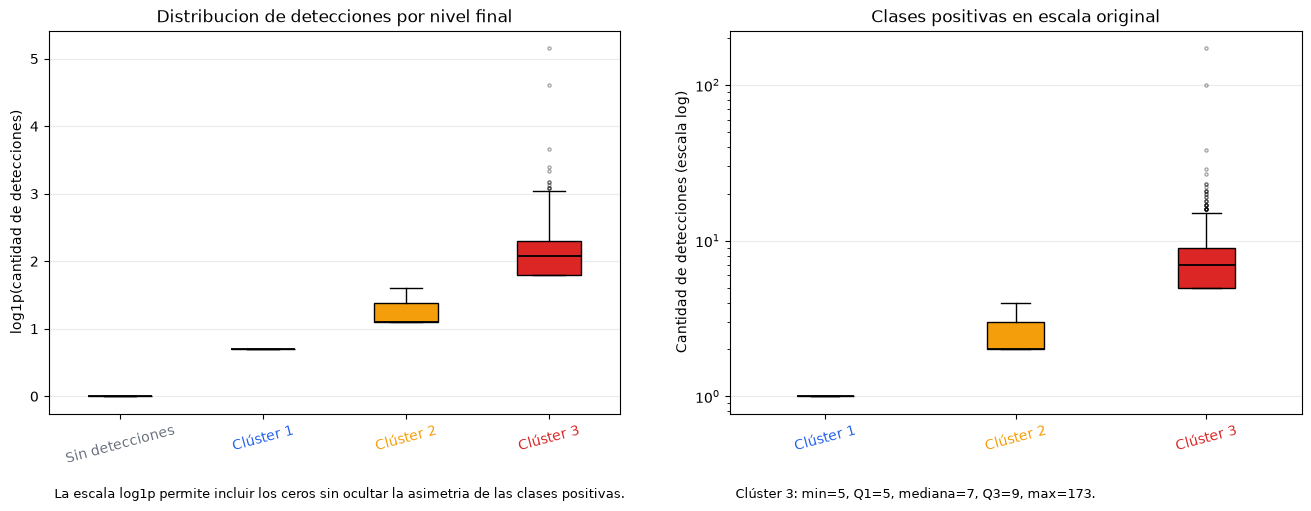

In [3]:
point4 = firms.point4_summary(data)
display(point4.round(4))

fig = firms.plot_point4_distribution(data, point4, close=False)
plt.show()

**Interpretación.** `Sin detecciones` concentra 4967 observaciones (62.69% del total) y todos sus valores son cero. `Clúster 1` queda fijado en una detección; `Clúster 2` agrupa semanas de 2 a 4 detecciones. `Clúster 3` conserva el rango 5-173, pero su mediana es 7, Q3 es 9 y la media es 8.61; esto muestra una clase con muchas semanas relativamente cercanas al umbral inferior y una cola de eventos excepcionalmente altos.

In [4]:
alto = point4.loc[point4[firms.TARGET].eq("Clúster 3")].iloc[0]
bajo = point4.loc[point4[firms.TARGET].eq("Clúster 1")].iloc[0]
moderado = point4.loc[point4[firms.TARGET].eq("Clúster 2")].iloc[0]
print(
    f"Interpretacion: Clúster 1 queda concentrado en {bajo['minimo']:.0f} deteccion. "
    f"Clúster 2 cubre {moderado['minimo']:.0f}-{moderado['maximo']:.0f}. "
    f"Clúster 3 conserva el rango {alto['minimo']:.0f}-{alto['maximo']:.0f}, "
    f"pero su mediana es {alto['mediana']:.0f} y Q3={alto['q3']:.0f}; "
    "por tanto, el maximo representa una cola alta, no el caso tipico."
)

Interpretacion: Clúster 1 queda concentrado en 1 deteccion. Clúster 2 cubre 2-4. Clúster 3 conserva el rango 5-173, pero su mediana es 7 y Q3=9; por tanto, el maximo representa una cola alta, no el caso tipico.


## Punto 6.1: método del codo e inercia de K-Means

Objetivo: comparar K=2,3,4,5 sobre la misma población positiva y la misma transformación `log1p(cantidad_detecciones)`.

,k,inertia,silhouette,cluster_minimo,porcentaje_minimo_positivas
0,2,265.6302,0.6770,1060,35.8593
1,3,121.8548,0.7445,453,15.3248
2,4,60.3837,0.7850,174,5.8863
3,5,34.0906,0.8608,106,3.5859


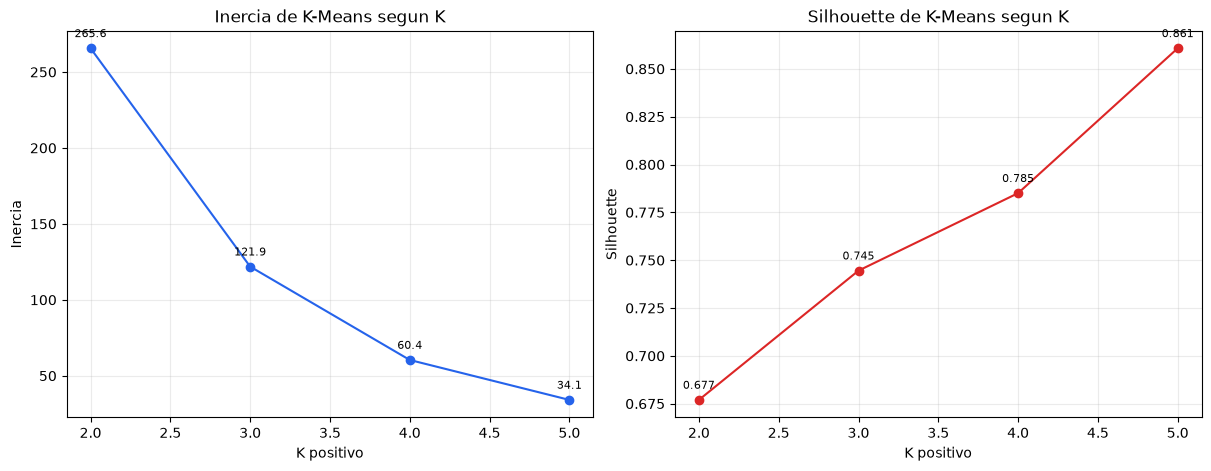

In [5]:
kmetrics = pd.read_csv(firms.TABLES / "punto6_kmeans_metricas_k_2_5.csv")
display(kmetrics.round(4))
fig = firms.plot_kmeans_metrics(kmetrics, close=False)
plt.show()

**Interpretación.** La inercia cae de 265.63 con k=2 a 34.09 con k=5, y Silhouette sube de 0.677 a 0.861. Sin embargo, el cluster positivo menor baja de 453 casos con k=3 a 106 con k=5. Por eso k mayores separan mejor algunos conteos en sentido geométrico, pero fragmentan la señal en clases más pequeñas.

In [6]:
print(
    "Interpretacion: la inercia baja al aumentar K, pero la mejora debe leerse junto "
    "con Silhouette y el tamano minimo de los grupos. Silhouette no decide sola, "
    "porque K mayores fragmentan los conteos positivos en clases mas pequenas."
)

Interpretacion: la inercia baja al aumentar K, pero la mejora debe leerse junto con Silhouette y el tamano minimo de los grupos. Silhouette no decide sola, porque K mayores fragmentan los conteos positivos en clases mas pequenas.


## Punto 6.2: boxplot de detecciones por perfil positivo

Objetivo: visualizar la dispersión de `Clúster 1`, `Clúster 2` y `Clúster 3` sin que la cola alta vuelva ilegible el gráfico.

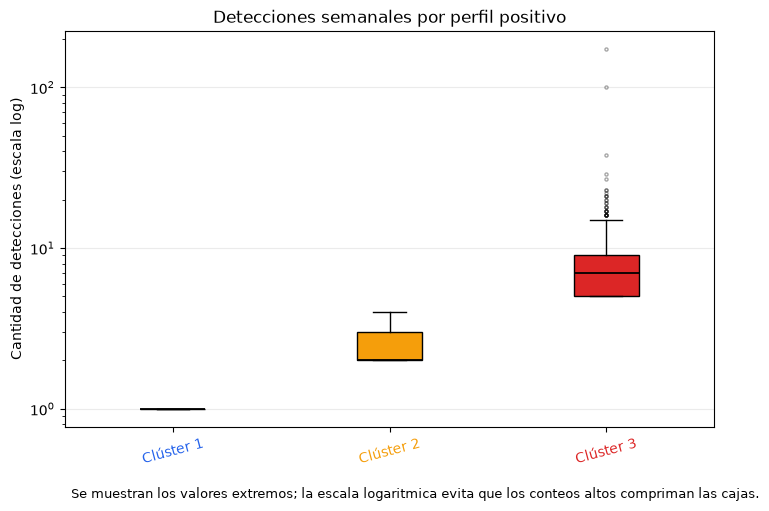

In [7]:
fig = firms.plot_positive_boxplot(data, close=False)
plt.show()

**Interpretación.** El gráfico confirma que `Clúster 1` no tiene dispersión porque corresponde a una detección. `Clúster 2` concentra valores entre 2 y 4. `Clúster 3` tiene una mediana baja dentro de su rango (7), pero incluye valores extremos hasta 173; por eso la escala logarítmica ayuda a ver la caja sin ocultar la cola.

In [8]:
print(
    "Interpretacion: se muestran valores extremos y se usa escala logaritmica en la escala original "
    "de conteos. Esto permite ver simultaneamente la concentracion de cada clase y la cola de Clúster 3."
)

Interpretacion: se muestran valores extremos y se usa escala logaritmica en la escala original de conteos. Esto permite ver simultaneamente la concentracion de cada clase y la cola de Clúster 3.


## Punto 6.3: boxplot de temperatura por nivel

Objetivo: comparar la temperatura máxima media semanal entre las cuatro clases finales.

,nivel_actividad_firms,validos_temperature_2m_max_mean_weekly
0,Sin detecciones,4967
1,Clúster 1,1237
2,Clúster 2,1266
3,Clúster 3,453


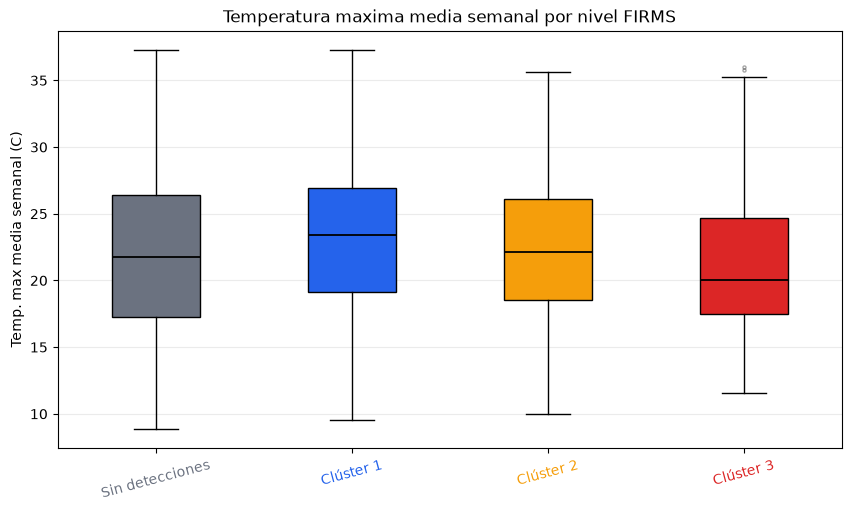

In [9]:
fig = firms.plot_meteo_boxplot(
    data,
    "temperature_2m_max_mean_weekly",
    "punto6_03_boxplot_temperatura_por_nivel.png",
    "Temperatura maxima media semanal por nivel FIRMS",
    close=False,
)
display(pd.read_csv(firms.TABLES / "punto6_03_boxplot_temperatura_por_nivel_observaciones_validas.csv"))
plt.show()

**Interpretación.** En medianas, la temperatura máxima media semanal más alta aparece en `Clúster 1` (23.41 °C). Las distribuciones se solapan, de modo que el gráfico sugiere asociación descriptiva, no una regla suficiente para separar las clases ni evidencia causal.

In [10]:
print(
    "Interpretacion: el grafico compara medianas, dispersion y extremos de temperatura por clase. "
    "Es evidencia descriptiva; no implica causalidad ni significacion estadistica."
)

Interpretacion: el grafico compara medianas, dispersion y extremos de temperatura por clase. Es evidencia descriptiva; no implica causalidad ni significacion estadistica.


## Punto 6.4: boxplot de humedad por nivel

Objetivo: comparar la humedad relativa mínima media semanal entre las cuatro clases finales, con la misma organización visual que temperatura.

,nivel_actividad_firms,validos_relative_humidity_2m_min_mean_weekly
0,Sin detecciones,4967
1,Clúster 1,1237
2,Clúster 2,1266
3,Clúster 3,453


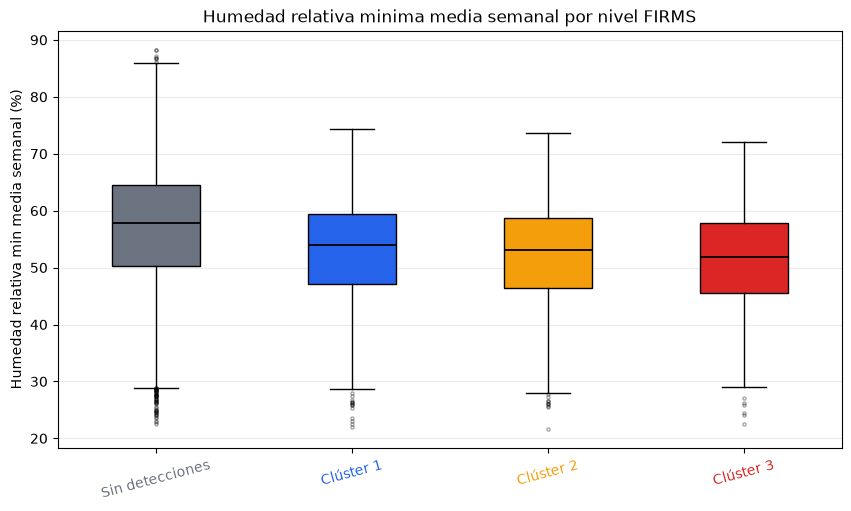

In [11]:
fig = firms.plot_meteo_boxplot(
    data,
    "relative_humidity_2m_min_mean_weekly",
    "punto6_04_boxplot_humedad_por_nivel.png",
    "Humedad relativa minima media semanal por nivel FIRMS",
    close=False,
)
display(pd.read_csv(firms.TABLES / "punto6_04_boxplot_humedad_por_nivel_observaciones_validas.csv"))
plt.show()

**Interpretación.** La humedad presenta diferencias de posición entre clases, pero también solapamiento. No se observan nulos en las variables meteorológicas usadas, por lo que las comparaciones mantienen el mismo conjunto de observaciones por clase.

In [12]:
print(
    "Interpretacion: el grafico resume diferencias descriptivas de humedad entre niveles. "
    "Las observaciones validas permiten verificar que no hay cambios de denominador por nulos."
)

Interpretacion: el grafico resume diferencias descriptivas de humedad entre niveles. Las observaciones validas permiten verificar que no hay cambios de denominador por nulos.


## Punto 6.5: heatmap de variables meteorológicas

Objetivo: resumir temperatura, humedad, viento y precipitación por clase sin mezclar escalas heterogéneas.

,temperature_2m_max_mean_weekly,relative_humidity_2m_min_mean_weekly,wind_speed_10m_max_mean_weekly,precipitation_sum_weekly
nivel_actividad_firms,,,,
Sin detecciones,21.733,57.886,5.504,14.300
Clúster 1,23.412,54.010,5.436,10.240
Clúster 2,22.119,53.047,5.483,9.014
Clúster 3,20.041,51.857,5.420,4.793


,nivel_actividad_firms,temperature_2m_max_mean_weekly,relative_humidity_2m_min_mean_weekly,wind_speed_10m_max_mean_weekly,precipitation_sum_weekly
0,Clúster 3,0,0,0,0
1,Clúster 1,0,0,0,0
2,Clúster 2,0,0,0,0
3,Sin detecciones,0,0,0,0


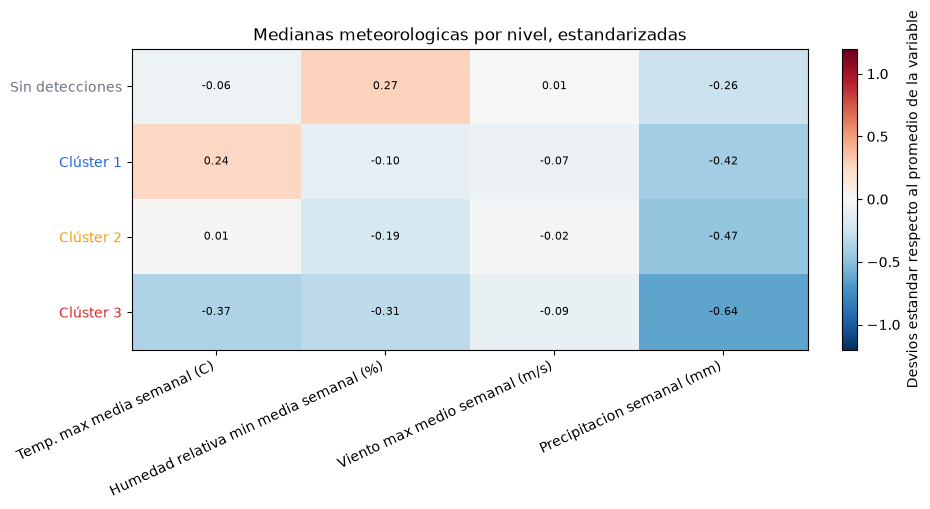

In [13]:
meteo_medians, fig = firms.heatmap_meteo(data, close=False)
display(meteo_medians.round(3))
display(pd.read_csv(firms.TABLES / "punto6_meteo_nulos_por_clase.csv"))
plt.show()

**Interpretación.** El heatmap estandariza las medianas para comparar variables con unidades distintas. La precipitación semanal mediana más baja aparece en `Clúster 3` (4.79 mm). Esta lectura es descriptiva: permite ver perfiles relativos, no afirmar que una variable meteorológica cause el nivel de actividad.

In [14]:
print(
    "Interpretacion: el heatmap usa medianas por clase estandarizadas por variable. "
    "Los colores indican desvios respecto al promedio de cada variable, no valores absolutos comparables entre magnitudes."
)

Interpretacion: el heatmap usa medianas por clase estandarizadas por variable. Los colores indican desvios respecto al promedio de cada variable, no valores absolutos comparables entre magnitudes.


## Punto 6.6: distribución de niveles por departamento

Objetivo: comparar la composición porcentual de niveles FIRMS en los 19 departamentos, usando como denominador el total de observaciones de cada departamento.

nivel_actividad_firms,Sin detecciones,Clúster 1,Clúster 2,Clúster 3
departamento,,,,
Lavalleja,196,79,103,39
Artigas,211,69,99,38
Cerro Largo,213,99,76,29
Rocha,216,74,87,40
San José,225,84,85,23
Treinta y Tres,226,70,95,26
Tacuarembó,229,75,71,42
Soriano,233,81,72,31
Colonia,260,54,73,30


nivel_actividad_firms,Sin detecciones,Clúster 1,Clúster 2,Clúster 3
departamento,,,,
Lavalleja,47.00,18.94,24.70,9.35
Artigas,50.60,16.55,23.74,9.11
Cerro Largo,51.08,23.74,18.23,6.95
Rocha,51.80,17.75,20.86,9.59
San José,53.96,20.14,20.38,5.52
Treinta y Tres,54.20,16.79,22.78,6.24
Tacuarembó,54.92,17.99,17.03,10.07
Soriano,55.88,19.42,17.27,7.43
Colonia,62.35,12.95,17.51,7.19


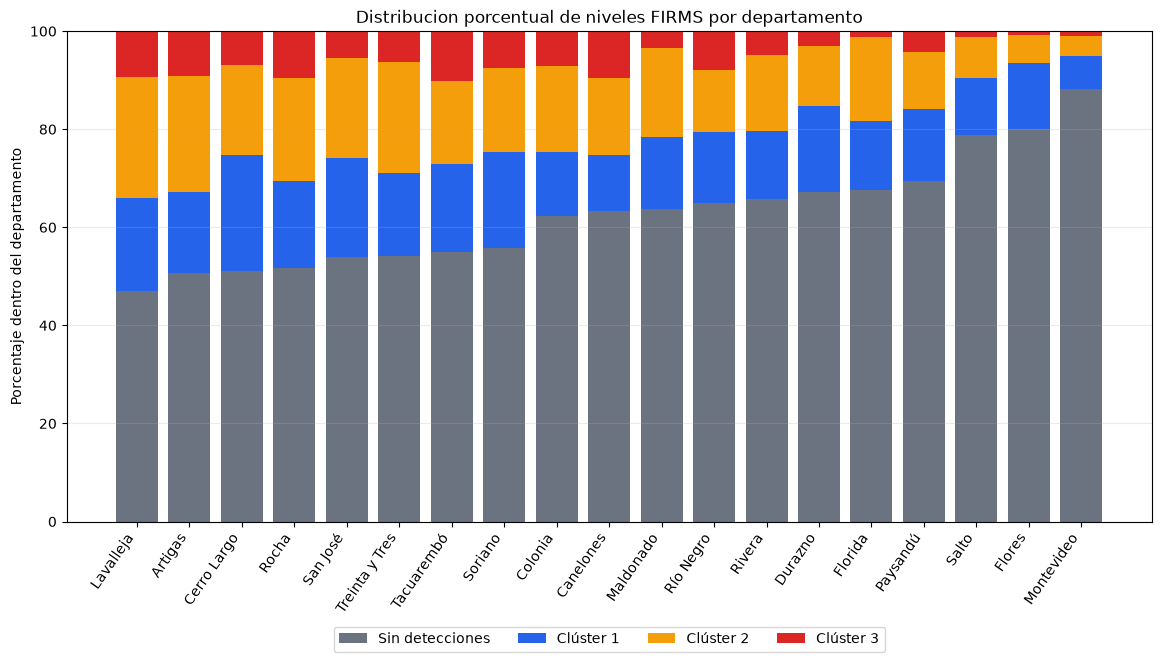

In [15]:
dept_counts, dept_props, fig = firms.department_distribution(data, close=False)
display(dept_counts)
display(dept_props.round(2))
plt.show()

**Interpretación.** Las barras usan porcentajes dentro de cada departamento. El mayor porcentaje combinado de clases positivas aparece en `Lavalleja` (53.00%). Esto permite comparar composición territorial sin que un departamento parezca más activo solo por tener más filas.

In [16]:
row_sums = dept_props[firms.ORDER].sum(axis=1).round(6)
print(f"Validacion: minimo={row_sums.min():.6f}, maximo={row_sums.max():.6f}; las proporciones por departamento suman 100%.")
print(
    "Interpretacion: las barras apiladas al 100% comparan perfiles territoriales sin confundir mayor cantidad total de filas "
    "con mayor actividad relativa."
)

Validacion: minimo=100.000000, maximo=100.000000; las proporciones por departamento suman 100%.
Interpretacion: las barras apiladas al 100% comparan perfiles territoriales sin confundir mayor cantidad total de filas con mayor actividad relativa.


## Punto 6.7: Precision, Recall y F1 por clase del Random Forest

Objetivo: mostrar el desempeño por clase del Random Forest V1 final en el split de test ya definido.

,escenario,n_clases,train_validation,test,f1_macro_test,balanced_accuracy_test
0,k3,4,6734,1189,0.3967,0.4137


,escenario,clase,precision,recall,f1,support
0,k3,Sin detecciones,0.7885,0.7007,0.7420,745.0
1,k3,Clúster 1,0.2402,0.2634,0.2513,186.0
2,k3,Clúster 2,0.3088,0.3526,0.3292,190.0
3,k3,Clúster 3,0.2170,0.3382,0.2644,68.0


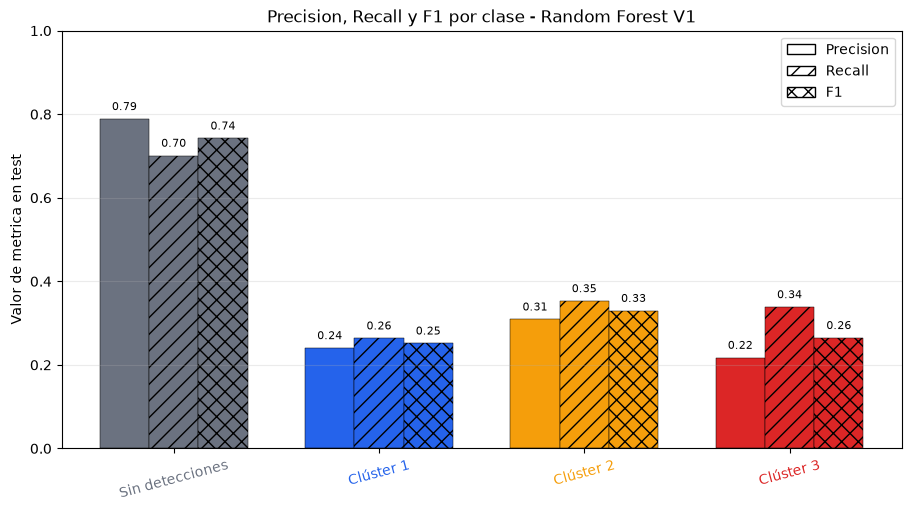

In [17]:
from src.refresh_presentation import saved_sensitivity
sensitivity = saved_sensitivity()
global_k3 = sensitivity["global_metrics"].query("escenario == 'k3'").iloc[0].to_dict()
rf_class_metrics = sensitivity["per_class"].query("escenario == 'k3'")
cm_k3 = sensitivity["confusion_matrices"]["k3"]
display(pd.DataFrame([global_k3]).round(4))
display(rf_class_metrics.round(4))
fig = firms.plot_rf_class_metrics(rf_class_metrics, close=False)
plt.show()

**Interpretación.** En test, el modelo reconoce mejor `Sin detecciones` (F1=0.742) que las clases positivas. La clase más débil en k=3 es `Clúster 1` (F1=0.251). Esto indica que el modelo capta parte de la diferencia entre semanas sin actividad y con actividad, pero tiene dificultades para separar niveles positivos cercanos.

In [18]:
worst = rf_class_metrics.sort_values("f1").iloc[0]
print(
    f"Interpretacion: la clase con menor F1 en test es {worst['clase']} "
    f"(F1={worst['f1']:.3f}). Las clases positivas son mas dificiles que Sin detecciones."
)

Interpretacion: la clase con menor F1 en test es Clúster 1 (F1=0.251). Las clases positivas son mas dificiles que Sin detecciones.


## Plus: análisis de sensibilidad con k=3, k=4 y k=5

Objetivo: aislar el efecto de cambiar la discretización del target positivo. Se mantienen las mismas observaciones, claves departamento-semana, variables V1, splits e hiperparámetros del Random Forest.

,escenario,n_clases,train_validation,test,f1_macro_test,balanced_accuracy_test
0,k3,4,6734,1189,0.3967,0.4137
1,k4,5,6734,1189,0.3371,0.3636
2,k5,6,6734,1189,0.2669,0.2836


,escenario,clase,observaciones,minimo,maximo,media,mediana,k,porcentaje_dataset
0,k3,Sin detecciones,4967,0,0,0.0000,0.0,3,62.6909
1,k3,Clúster 1,1237,1,1,1.0000,1.0,3,15.6128
2,k3,Clúster 2,1266,2,4,2.6627,2.0,3,15.9788
3,k3,Clúster 3,453,5,173,8.6093,7.0,3,5.7175
4,k4,Sin detecciones,4967,0,0,0.0000,0.0,4,62.6909
5,k4,Perfil positivo 1,1237,1,1,1.0000,1.0,4,15.6128
6,k4,Perfil positivo 2,1034,2,3,2.3627,2.0,4,13.0506
7,k4,Perfil positivo 3,511,4,7,4.9648,5.0,4,6.4496
8,k4,Perfil positivo 4,174,8,173,13.1667,10.0,4,2.1961
9,k5,Sin detecciones,4967,0,0,0.0000,0.0,5,62.6909


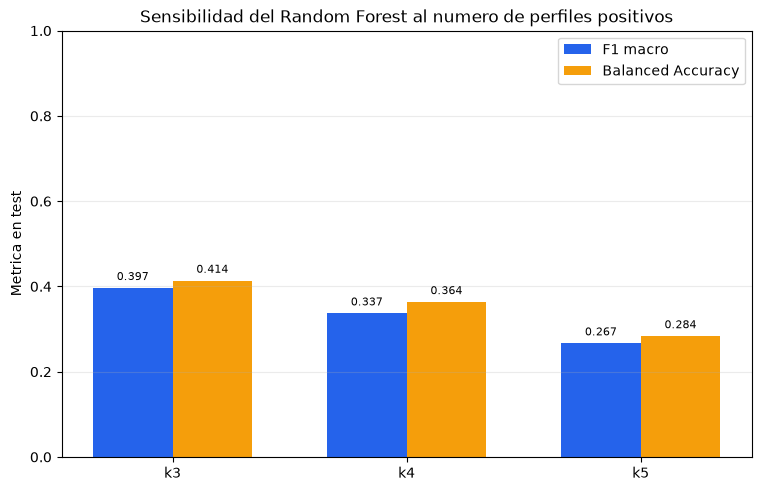

In [19]:
sensitivity = saved_sensitivity()
global_metrics = sensitivity["global_metrics"]
class_summary = sensitivity["class_summary"]
per_class = sensitivity["per_class"]
confusion_matrices = sensitivity["confusion_matrices"]

display(global_metrics.round(4))
display(class_summary.round(4))
fig = firms.plot_plus_global(global_metrics, close=False)
plt.show()

**Interpretación.** La sensibilidad no mejora al aumentar K: k=3 obtiene F1 macro=0.3967 y Balanced Accuracy=0.4137; k=4 baja a 0.3371/0.3636; k=5 baja a 0.2669/0.2836. Además, con k=5 aparece una clase de solo 106 observaciones (1.34% del dataset).

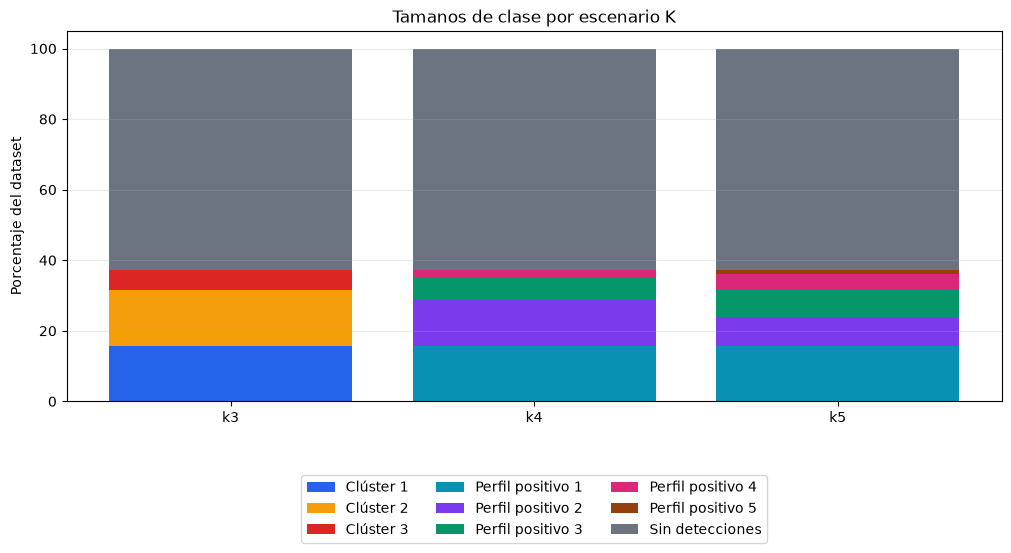

In [20]:
fig = firms.plot_plus_class_sizes(class_summary, close=False)
plt.show()

**Interpretación.** El aumento de K no crea solamente más detalle semántico: divide grupos positivos existentes en clases progresivamente más chicas. Esa fragmentación puede ser útil para describir conteos, pero dificulta el aprendizaje supervisado porque cada clase aporta menos ejemplos.

,escenario,clase,precision,recall,f1,support
0,k3,Sin detecciones,0.7885,0.7007,0.7420,745.0
1,k3,Clúster 1,0.2402,0.2634,0.2513,186.0
2,k3,Clúster 2,0.3088,0.3526,0.3292,190.0
3,k3,Clúster 3,0.2170,0.3382,0.2644,68.0
4,k4,Sin detecciones,0.7791,0.6819,0.7273,745.0
5,k4,Perfil positivo 1,0.2217,0.2527,0.2362,186.0
6,k4,Perfil positivo 2,0.2486,0.2866,0.2663,157.0
7,k4,Perfil positivo 3,0.1875,0.2368,0.2093,76.0
8,k4,Perfil positivo 4,0.1875,0.3600,0.2466,25.0
9,k5,Sin detecciones,0.7840,0.6819,0.7294,745.0


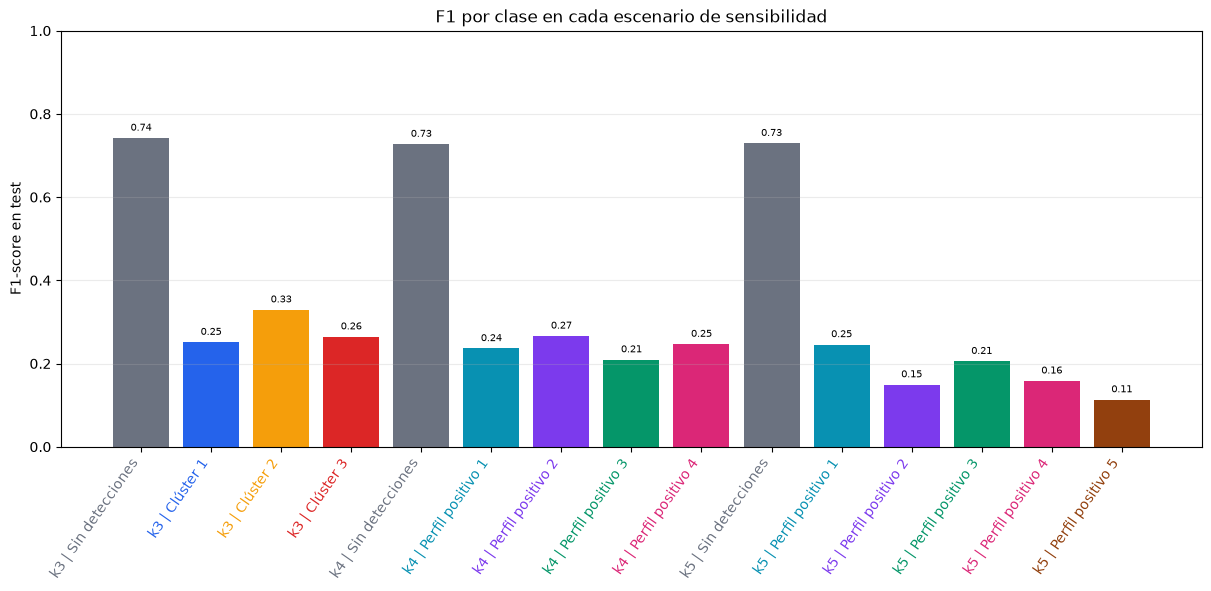

In [21]:
display(per_class.round(4))
fig = firms.plot_plus_f1(per_class, close=False)
plt.show()

**Interpretación.** Los F1 por clase muestran que las nuevas clases de k=4 y k=5 no se reconocen de manera uniforme. Las clases más pequeñas, especialmente el perfil positivo más alto de k=5, tienen pocos casos de test y F1 bajo, por lo que una métrica global no debe leerse como mejora general de todas las categorías.

Matriz de confusion - k3


,Sin detecciones,Clúster 1,Clúster 2,Clúster 3
real,,,,
Sin detecciones,522,106,84,33
Clúster 1,72,49,46,19
Clúster 2,53,39,67,31
Clúster 3,15,10,20,23


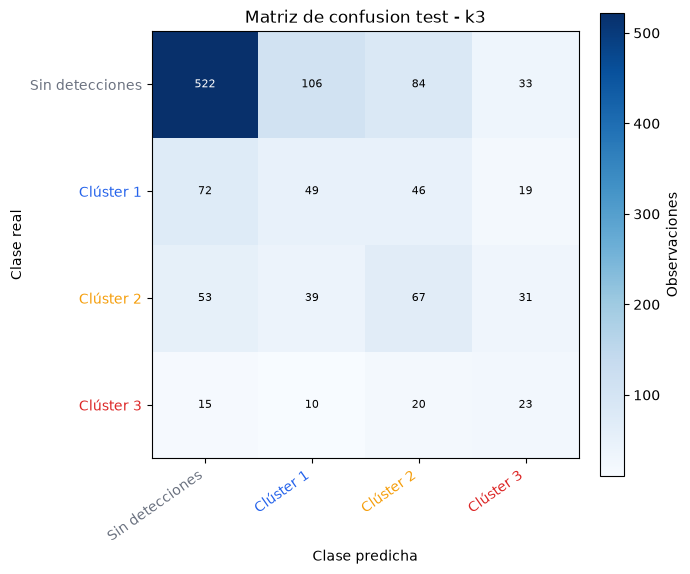

Matriz de confusion - k4


,Sin detecciones,Perfil positivo 1,Perfil positivo 2,Perfil positivo 3,Perfil positivo 4
real,,,,,
Sin detecciones,508,119,75,27,16
Perfil positivo 1,74,47,37,18,10
Perfil positivo 2,47,31,45,27,7
Perfil positivo 3,19,11,22,18,6
Perfil positivo 4,4,4,2,6,9


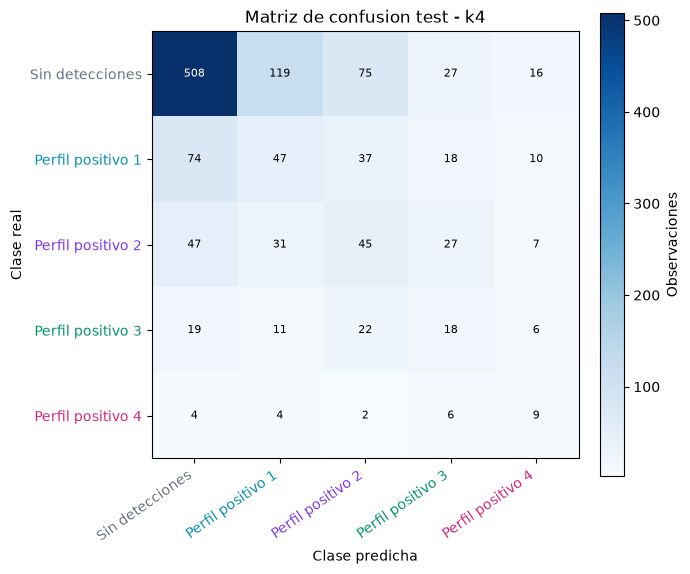

Matriz de confusion - k5


,Sin detecciones,Perfil positivo 1,Perfil positivo 2,Perfil positivo 3,Perfil positivo 4,Perfil positivo 5
real,,,,,,
Sin detecciones,508,130,40,26,28,13
Perfil positivo 1,67,50,22,25,14,8
Perfil positivo 2,37,19,15,12,10,4
Perfil positivo 3,21,13,16,19,20,4
Perfil positivo 4,12,7,9,8,11,4
Perfil positivo 5,3,2,2,2,5,3


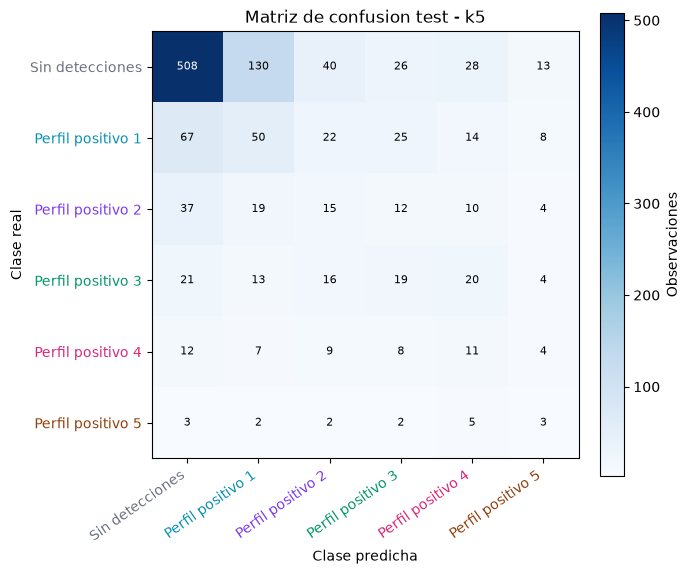

In [22]:
for scenario, cm in confusion_matrices.items():
    print(f"Matriz de confusion - {scenario}")
    display(cm)
    fig = firms.plot_confusion(cm, scenario, close=False)
    plt.show()

**Interpretación.** Las matrices de confusión muestran que muchas semanas positivas se reparten entre clases vecinas o se predicen como `Sin detecciones`. En términos del problema, confundir `Clúster 3` con `Clúster 2` implica subestimar el orden del grupo según sus centroides de conteos; confundir `Sin detecciones` con `Clúster 1` implica marcar actividad donde no hubo detecciones.

In [23]:
best = global_metrics.sort_values(["f1_macro_test", "balanced_accuracy_test"], ascending=False).iloc[0]
smallest = class_summary.sort_values(["escenario", "observaciones"]).groupby("escenario").first().reset_index()
display(smallest[["escenario", "clase", "observaciones", "porcentaje_dataset"]].round(4))
print(
    f"Conclusion: dentro de esta sensibilidad, el mayor F1 macro de test queda en {best['escenario']} "
    f"({best['f1_macro_test']:.3f}). Al aumentar K, aparecen clases positivas mas chicas y el desempeno global baja; "
    "esto respalda que k=3 ofrece una particion mas simple e interpretable para este proyecto, sin usar test para redisenar el modelo."
)

,escenario,clase,observaciones,porcentaje_dataset
0,k3,Clúster 3,453,5.7175
1,k4,Perfil positivo 4,174,2.1961
2,k5,Perfil positivo 5,106,1.3379


Conclusion: dentro de esta sensibilidad, el mayor F1 macro de test queda en k3 (0.397). Al aumentar K, aparecen clases positivas mas chicas y el desempeno global baja; esto respalda que k=3 ofrece una particion mas simple e interpretable para este proyecto, sin usar test para redisenar el modelo.
